# 01. NEU dataset exploration

Questions this notebook answers before any model is trained:

1. Is the dataset what it claims to be (1,800 images, six balanced classes, 200x200 grayscale)?
2. Are there corrupt files or duplicates that could leak between train and test?
3. How do the classes differ in brightness, contrast and texture?
4. What do classical CV operations (CLAHE, filtering, edges, morphology, HOG) reveal per class?

All numbers come from the same functions the training pipeline uses (`idefect.data`).

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display


def show(path):
    # Display a saved figure at full resolution.
    display(Image(filename=str(path)))

from idefect.config import load_config
from idefect.data.datasets import build_split
from idefect.data.stats import audit_samples, audit_split, problems

cfg = load_config("configs/neu_baseline.yaml")
samples, class_names, split, dup_groups = build_split(cfg)
print(f"{len(samples)} images, classes: {class_names}")
print(split.summary(), f"| {len(dup_groups)} near-duplicate groups kept within one split")

1800 images, classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
6 classes | train=1260 val=271 test=269 | 248 near-duplicate groups kept within one split


## 1. Integrity checks

In [2]:
report = audit_samples(samples, class_names)
split_report = audit_split(split, report["duplicate_groups"], dup_groups)
print("image shapes :", report["image_shapes"])
print("dtypes       :", report["dtypes"], " channels:", report["channels"])
print("unreadable   :", len(report["unreadable_files"]))
print("identical files:", report["duplicate_groups"])
print("near-duplicate groups:", len(dup_groups), "covering", sum(len(g) for g in dup_groups), "images")
print("groups across splits (leakage):", len(split_report["near_duplicate_groups_across_splits"]))
print("problems     :", problems(report, split_report) or "none")
pd.DataFrame(split_report["class_distribution"])

image shapes : {'200x200': 1800}
dtypes       : {'uint8': 1800}  channels: {'1': 1800}
unreadable   : 0
identical files: [['data/raw/NEU-CLS/Pa_101.bmp', 'data/raw/NEU-CLS/Pa_105.bmp']]
near-duplicate groups: 248 covering 1583 images
groups across splits (leakage): 0
problems     : none


,train,val,test
crazing,210,45,45
inclusion,213,44,43
patches,210,45,45
pitted_surface,210,45,45
rolled-in_scale,210,45,45
scratches,207,47,46


Every image is a readable 200x200 single-channel `uint8` BMP and the classes are perfectly balanced
(300 each). One pair of files is byte-identical (`Pa_101.bmp`, `Pa_105.bmp`), but that is the smallest
part of the story: the near-duplicate detector (see `docs/methodology.md`) finds that most NEU images share
an exact region with other images (overlapping crops of the same strip, often flipped or rotated), plus
some re-processed copies. With a plain random split those relatives land on both sides of the boundary.
The pipeline keeps every group inside one split, and the check above confirms that no group spans two.

## 2. Samples per class

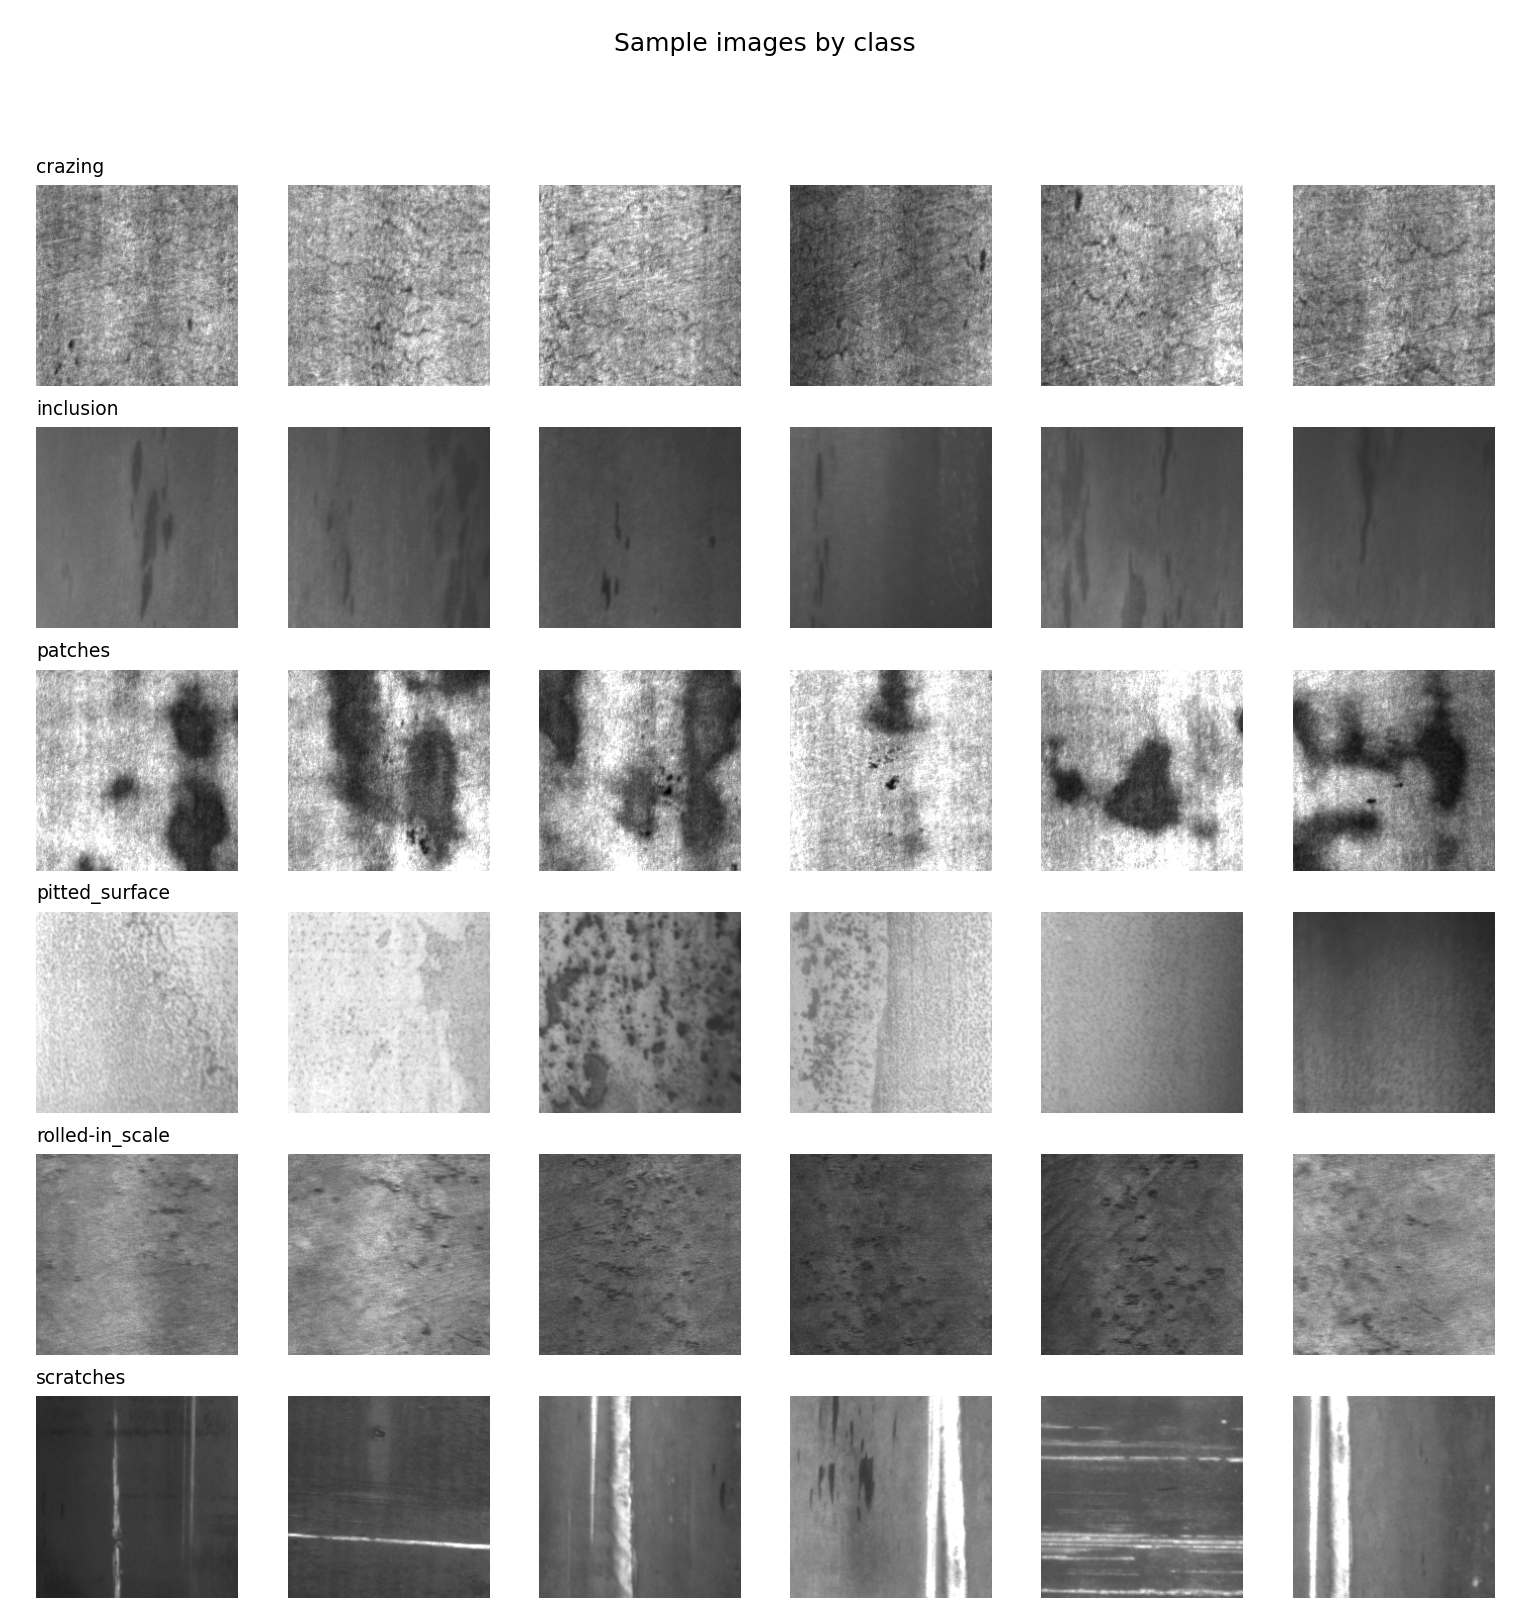

In [3]:
from idefect.visualization import eda
fig_dir = Path(cfg.output.figures_dir) / "eda"
show((eda.plot_samples_by_class(samples, class_names, fig_dir / "samples_by_class.png", seed=cfg.seed)))

Scratches appear both vertically and horizontally, and the other defects have no canonical orientation
either. This justifies flips and 90-degree rotations as label-preserving augmentation for the CNN.

## 3. Brightness and contrast per class

In [4]:
rows = []
for c, v in report["per_class_intensity"].items():
    rows.append({"class": c,
                 "mean intensity": v["mean"]["mean"], "spread of mean (std)": v["mean"]["std"],
                 "within-image std": v["std"]["mean"], "RMS contrast": v["rms_contrast"]["mean"]})
pd.DataFrame(rows).set_index("class").loc[class_names].round(2)

,mean intensity,spread of mean (std),within-image std,RMS contrast
class,,,,
crazing,141.08,28.58,28.85,0.11
inclusion,106.40,33.78,13.01,0.05
patches,132.56,43.02,54.18,0.21
pitted_surface,176.65,49.26,26.65,0.10
rolled-in_scale,117.92,24.54,15.87,0.06
scratches,95.18,29.02,21.69,0.09


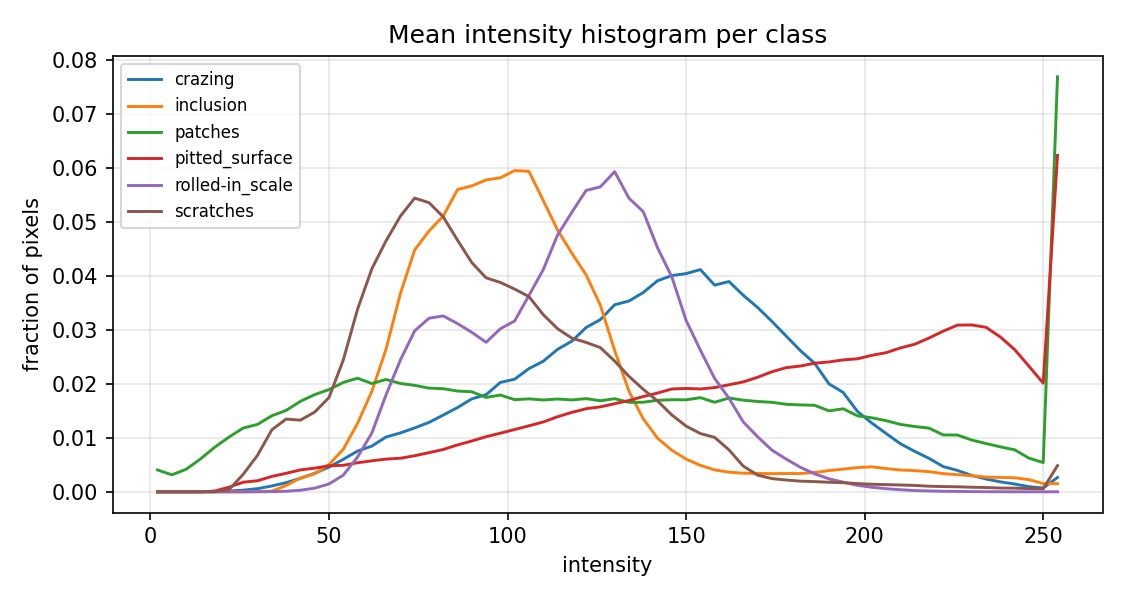

In [5]:
show((eda.plot_intensity_histograms(samples, class_names, fig_dir / "intensity_histograms.png")))

Observations:

* Patches have by far the highest within-image contrast (large dark blobs on a bright background), while
  inclusion and rolled-in scale are the flattest images.
* Mean brightness differs between classes (pitted surface brightest, scratches darkest) but the spread of
  the mean *within* each class is large (for example about 49 grey levels for pitted surface), so global
  brightness alone cannot separate the classes. This is one reason to normalise contrast (CLAHE) before
  extracting features, and a question revisited in the preprocessing ablation of the classical branch.

## 4. Mean image per class

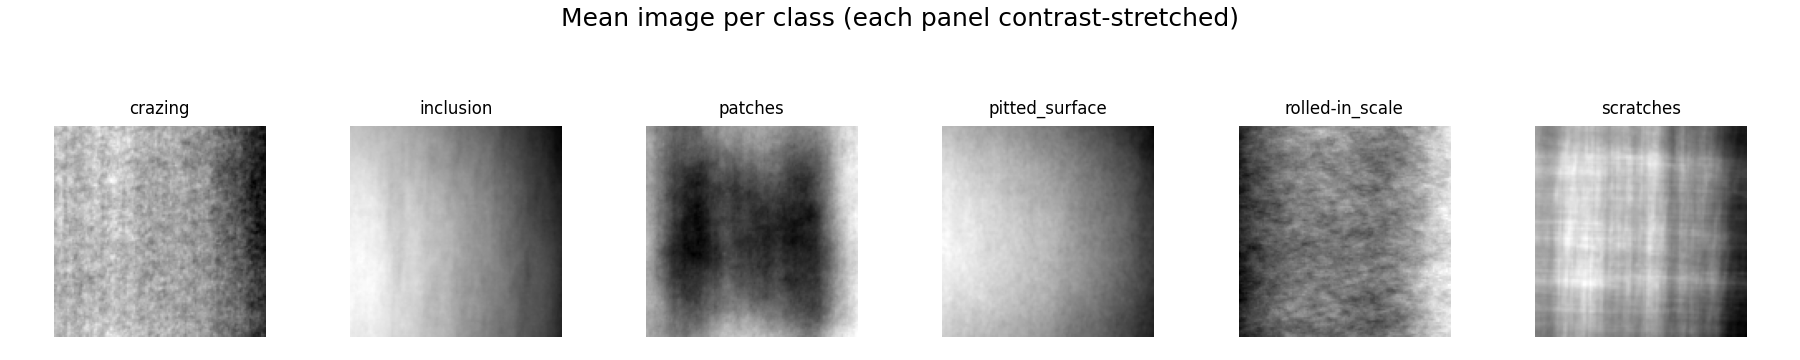

In [6]:
show((eda.plot_class_mean_images(samples, class_names, fig_dir / "class_mean_images.png", image_size=cfg.data.image_size)))

Each panel is contrast-stretched on its own, so these show *where* intensity varies, not absolute levels.

* Most classes darken towards the right edge: uneven illumination from the acquisition setup. This is
  a global trend unrelated to the defect, and one argument for *local* contrast normalisation (CLAHE)
  over a single global adjustment.
* Patches concentrate slightly towards the centre and scratches average into a grid of vertical and
  horizontal streaks, but no class has a strong location prior. Defects occur anywhere in the frame,
  which suits translation-invariant features (HOG and LBP histograms, convolution with global pooling).

## 5. Classical CV operations

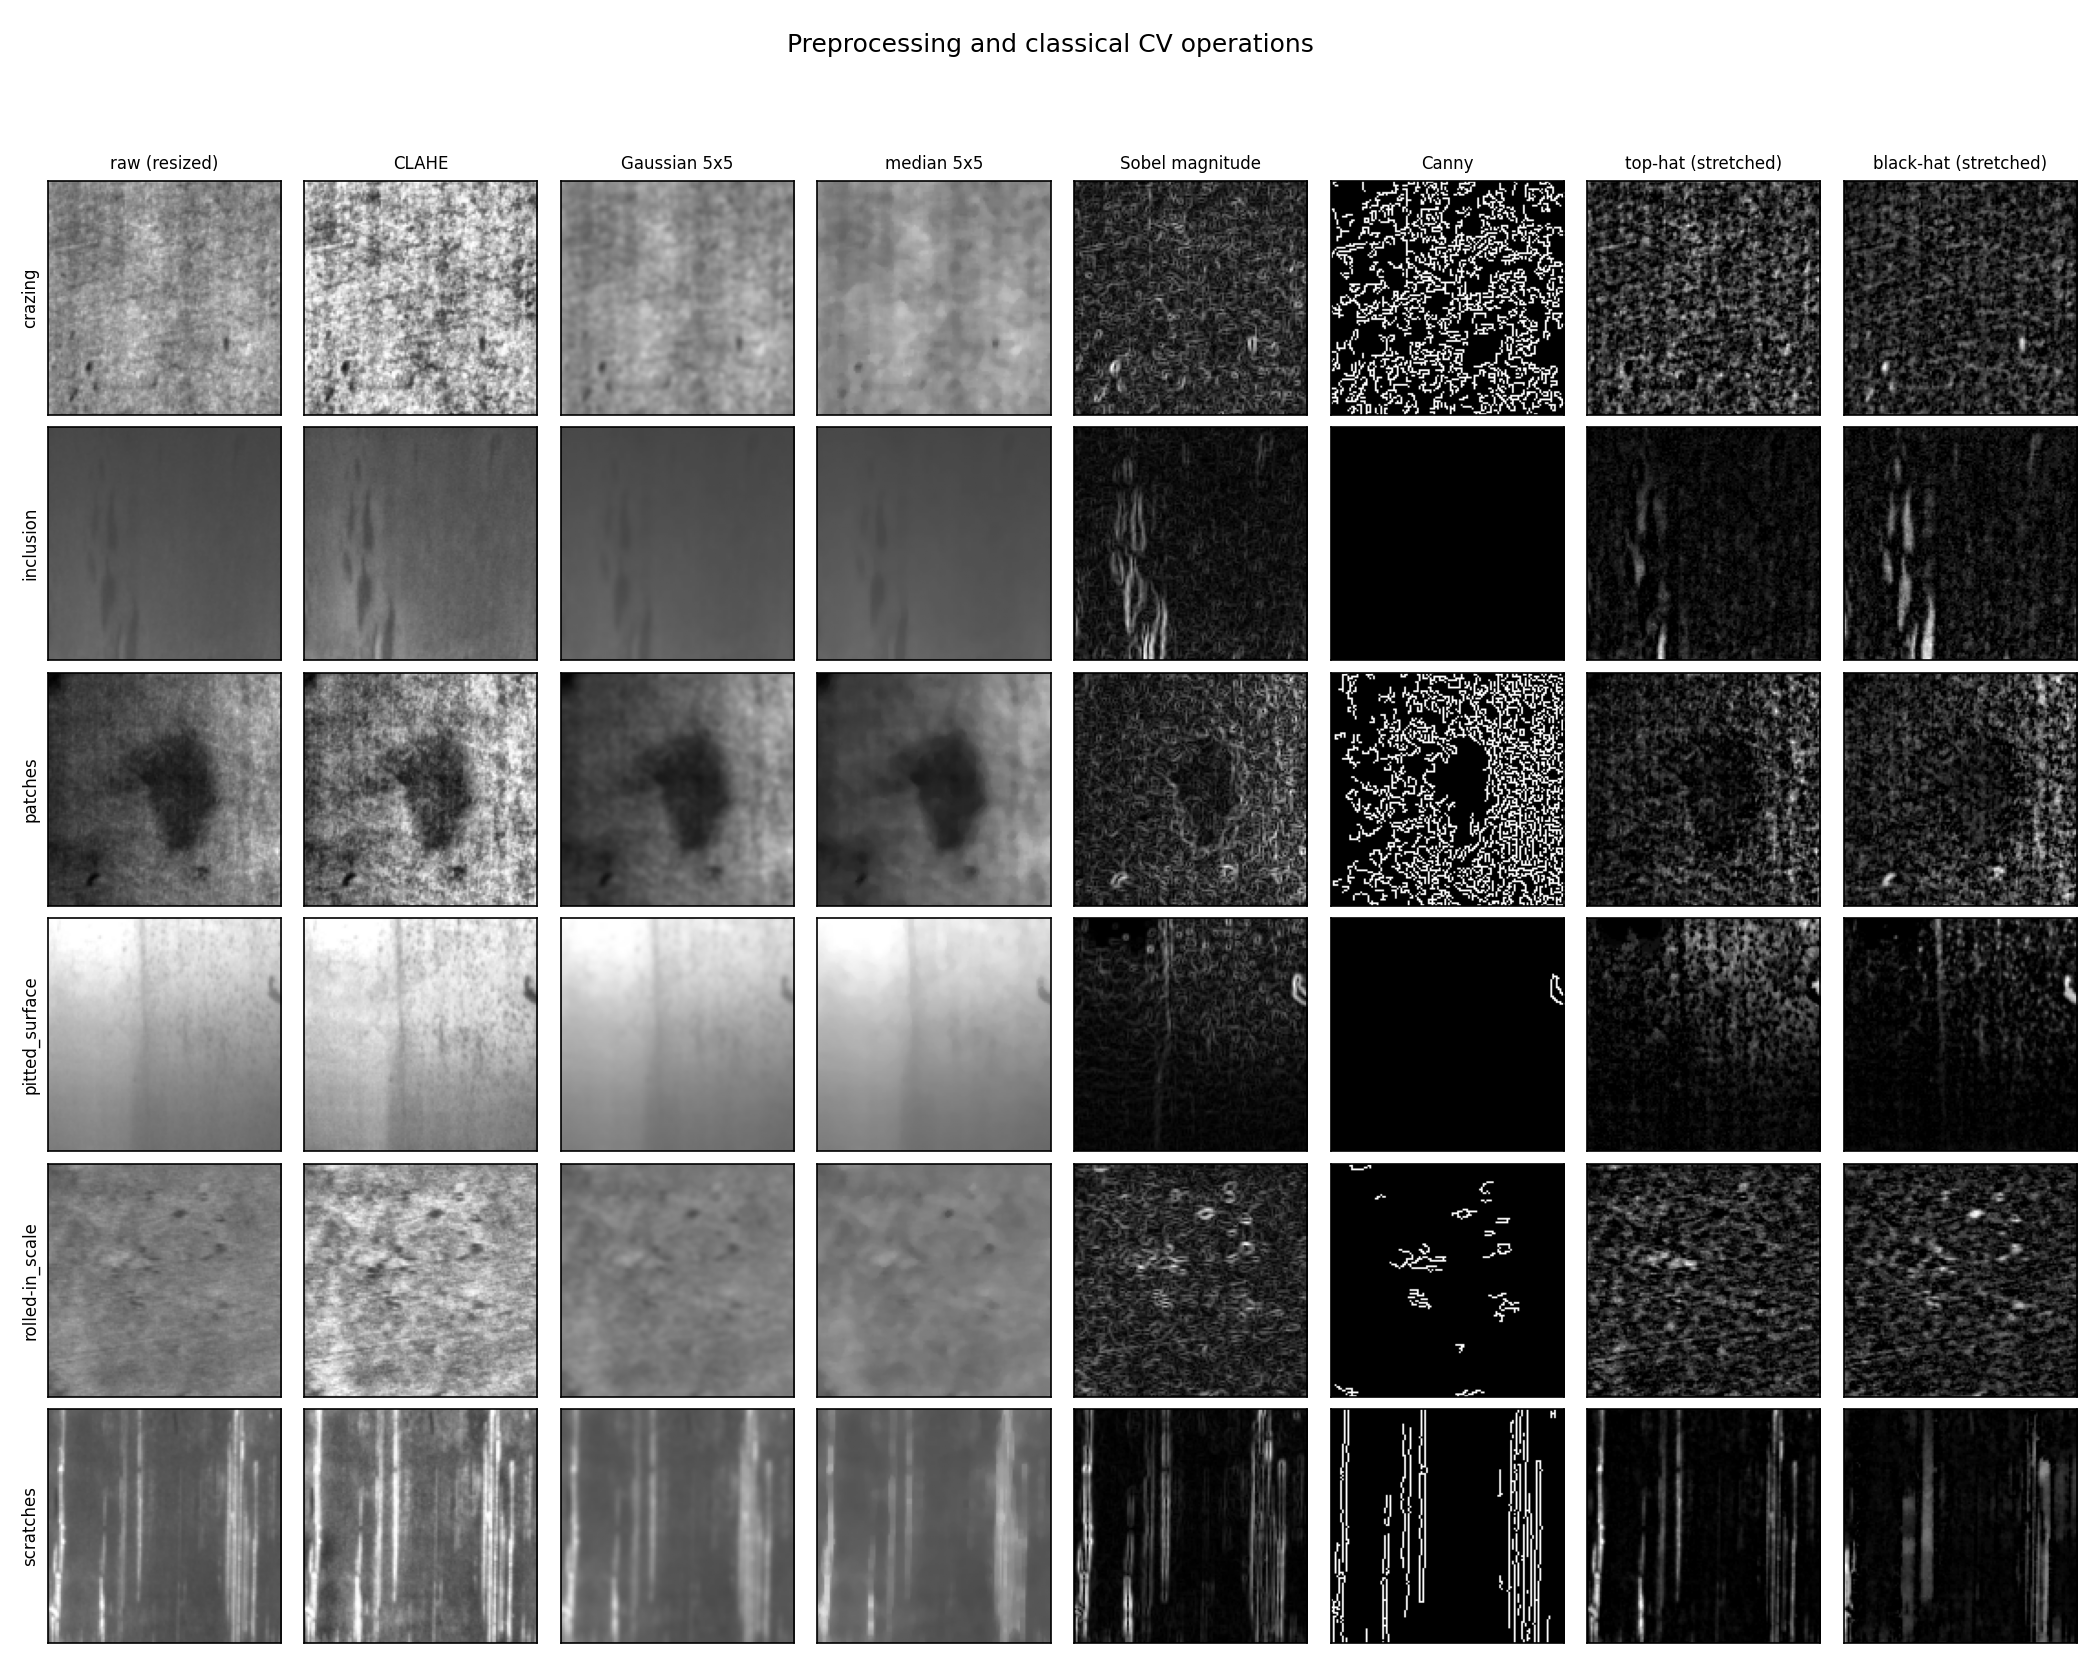

In [7]:
show((eda.plot_preprocessing_comparison(samples, class_names, fig_dir / "preprocessing_comparison.png", image_size=cfg.data.image_size, seed=cfg.seed)))

* **CLAHE** lifts faint structure (inclusion streaks, pits) without saturating bright images.
* **Gaussian / median filtering** suppresses the fine grain but also erodes the fine crazing network:
  denoising is a trade-off, not a free improvement, which is why it is off by default and studied as
  an ablation later.
* **Sobel / Canny** outline scratches and the crazing network crisply (gradient phenomena). On patches
  they fire on the fine grain of the bright background rather than on the soft boundary of the dark
  blobs, so the defining blob shape is barely encoded. This predicts the error pattern seen with HOG
  features: patches were the class the Phase 1 HOG + SVM baseline got wrong most often (F1 0.65).
* **Top-hat / black-hat** isolate small bright and dark details respectively (inclusions, pits).

## 6. HOG view per class

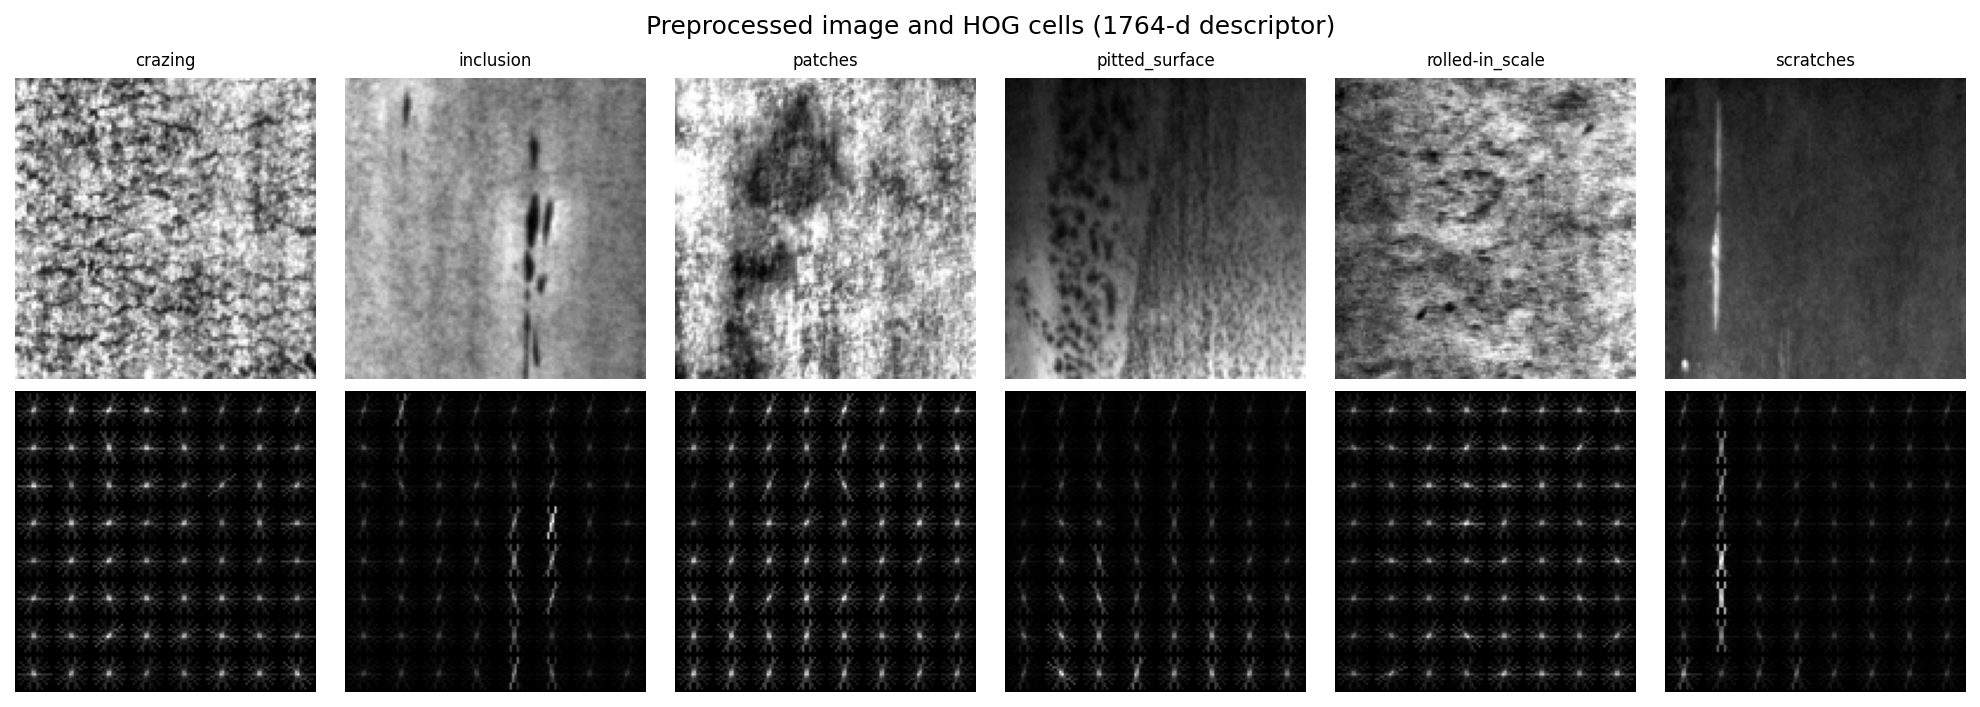

In [8]:
from idefect.data.preprocessing import load_and_preprocess
from idefect.features.hog import hog_visualization

by_class = {i: sorted(p for p, y in samples if y == i) for i in range(len(class_names))}
fig, axes = plt.subplots(2, len(class_names), figsize=(2.2 * len(class_names), 4.6), dpi=150,
                         layout="constrained")
for i, name in enumerate(class_names):
    img = load_and_preprocess(by_class[i][0], cfg.preprocessing, cfg.data.image_size)
    feats, hog_img = hog_visualization(img, cfg.hog)
    axes[0, i].imshow(img, cmap="gray"); axes[0, i].set_title(name, fontsize=8)
    axes[1, i].imshow(hog_img, cmap="gray")
    for ax in axes[:, i]:
        ax.axis("off")
fig.suptitle(f"Preprocessed image and HOG cells ({feats.size}-d descriptor)")
plt.show()

With 16x16 cells on a 128x128 image, HOG encodes 8x8 cells of 9 orientation bins, normalised in
overlapping 2x2 blocks: 7 x 7 blocks x 4 cells x 9 bins = 1,764 features. Scratches give a few strong,
consistent orientations; crazing gives many mixed orientations; patches and pitted surfaces give weak,
diffuse gradients, which is where a texture descriptor (LBP, GLCM) is expected to help.

## Summary

* Files are clean, balanced and consistent, but most images are related to others (overlapping
  crops, flips, rotations, re-processed copies: 248 groups covering 1,583 images). Group-aware
  splitting keeps every group inside one split, so no test image has a relative in training.
* Classes differ mainly in texture and local structure rather than global brightness or location.
* Gradient features should do well on scratches and crazing and struggle on patches and pitted surface;
  the Phase 1 HOG + SVM baseline confirmed this (F1 0.65 for patches and 0.75 for pitted surface,
  against 0.83 to 0.98 for the other classes). Notebooks 02 and 03 show how texture features close the gap.